In [5]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [126]:
S_0 = 1367      # [W/m2] solar constant at the mean Earth-Sun distance
lat = 50        # [deg] latitude
lon = 20        # [deg] longitude
lon_0 = 15      # [deg] reference meridian of my time zone
year = 2025     

phi = np.radians(lat)   



In [138]:
hours = pd.date_range(f"{year}-01-01 00:00", f"{year}-12-31 23:00", freq="h")  
df = pd.DataFrame(index=hours)
df["day"]  = df.index.dayofyear   
df["hour"] = df.index.hour        

print(len(df), "rows")
df.head()

8760 rows


,day,hour
2025-01-01 00:00:00,1,0
2025-01-01 01:00:00,1,1
2025-01-01 02:00:00,1,2
2025-01-01 03:00:00,1,3
2025-01-01 04:00:00,1,4


In [ ]:
### top of the atmosphere ###

<Axes: xlabel='Day of the year', ylabel='Energy at top of atmosphere [W/m2]'>

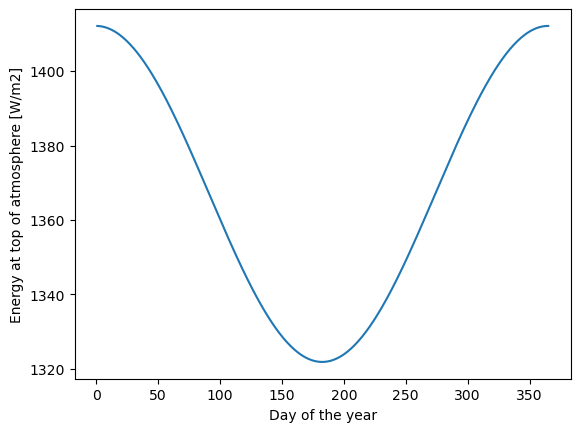

In [150]:
df["S_0d"] = S_0 * (1 + 0.033 * np.cos(2 * np.pi * df["day"] / 365))   # [W/m2]

df.groupby("day")["S_0d"].first().plot(xlabel="Day of the year", ylabel="Energy at top of atmosphere [W/m2]")

max decl: 23.44 deg on day 173
min decl: -23.46 deg on day 356


<Axes: xlabel='Day of the year', ylabel='Declination [deg]'>

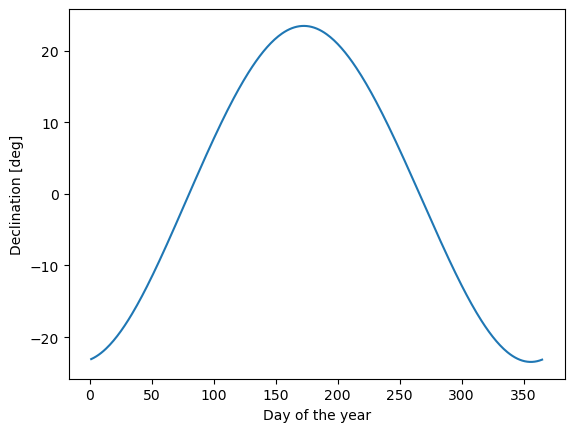

In [155]:
N = 2 * np.pi * df["day"] / 365

decl_deg = (0.33281
            - 22.984  * np.cos(N)     + 3.7872  * np.sin(N)
            - 0.3499  * np.cos(2 * N) + 0.03205 * np.sin(2 * N)
            - 0.1398  * np.cos(3 * N) + 0.07187 * np.sin(3 * N)) # [deg]

df["decl"] = np.radians(decl_deg) # [rad]

daily_decl = decl_deg.groupby(df["day"]).first()
print("max decl:", round(daily_decl.max(), 2), "deg on day", daily_decl.idxmax())
print("min decl:", round(daily_decl.min(), 2), "deg on day", daily_decl.idxmin())
daily_decl.plot(xlabel="Day of the year", ylabel="Declination [deg]")

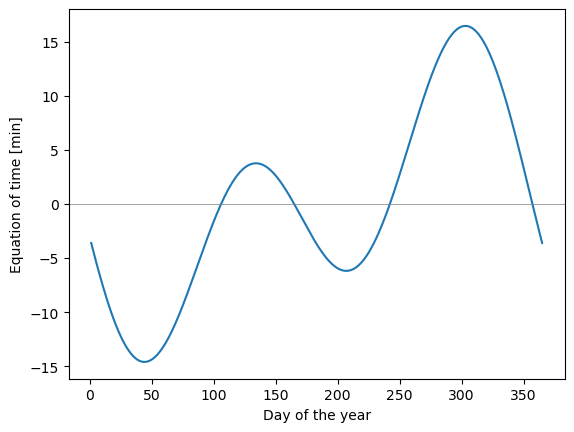

In [156]:
B = 2 * np.pi * (df["day"] - 81) / 364
eot = 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B) # equation of time [min]

df["eot"] = eot
df.groupby("day")["eot"].first().plot(xlabel="Day of the year", ylabel="Equation of time [min]")
plt.axhline(0, color="grey", lw=0.5);

In [157]:
correction_h = (4 * (lon - lon_0) + eot) / 60                     # solar time minus clock time [h]

df["tau_1"] = (df["hour"] + correction_h - 12) * 2 * np.pi / 24   # hour angle at start of the hour [rad]
df["tau_2"] = df["tau_1"] + 2 * np.pi / 24                        # hour angle at the end of the hour [rad]

In [177]:
tau_mid = (df["tau_1"] + df["tau_2"]) / 2

sin_h = np.sin(phi) * np.sin(df["decl"] + np.cos(phi) * np.cos(df["decl"] * np.cos(tau_mid)))
df["h"] = np.arcsin(sin_h)
df["I_0h"] = df["S_0d"] * np.sin(df["h"])

In [182]:
cos_ts = (-np.tan(phi) * np.tan(df["decl"]))
df["tau_s"] = np.arccos(cos_ts) # sunset hour angle [rad]

t1 = df["tau_1"].clip(lower=-df["tau_s"], upper=df["tau_s"])
t2 = df["tau_2"].clip(lower=-df["tau_s"], upper=df["tau_s"])

E_joule = 86400 / (2 * np.pi) * df["S_0d"] * (
    (t2 - t1) * np.sin(phi) * np.sin(df["decl"])
    + np.cos(phi) * np.cos(df["decl"]) * (np.sin(t2) - np.sin(t1))
)                                                            # [J/m2]
df["E_hour"] = E_joule / 3600                                # [Wh/m2]


In [183]:
df

,day,hour,S_0d,decl,eot,tau_1,tau_2,h,I_0h,tau_s,E_hour
2025-01-01 00:00:00,1,0,1412.104316,-0.402597,-3.606873,-3.070064,-2.808265,0.145829,205.196297,1.038496,0.0
2025-01-01 01:00:00,1,1,1412.104316,-0.402597,-3.606873,-2.808265,-2.546465,0.152015,213.835320,1.038496,0.0
2025-01-01 02:00:00,1,2,1412.104316,-0.402597,-3.606873,-2.546465,-2.284666,0.161346,226.850644,1.038496,0.0
2025-01-01 03:00:00,1,3,1412.104316,-0.402597,-3.606873,-2.284666,-2.022867,0.171350,240.781331,1.038496,0.0
2025-01-01 04:00:00,1,4,1412.104316,-0.402597,-3.606873,-2.022867,-1.761067,0.179333,251.881485,1.038496,0.0
...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31 19:00:00,365,19,1412.111000,-0.403885,-3.606873,1.904124,2.165924,0.174345,244.949831,1.036388,0.0
2025-12-31 20:00:00,365,20,1412.111000,-0.403885,-3.606873,2.165924,2.427723,0.164878,231.772322,1.036388,0.0
2025-12-31 21:00:00,365,21,1412.111000,-0.403885,-3.606873,2.427723,2.689522,0.154841,217.780079,1.036388,0.0
2025-12-31 22:00:00,365,22,1412.111000,-0.403885,-3.606873,2.689522,2.951322,0.146914,206.712884,1.036388,0.0


In [181]:
# sun below the horizon at both the start and the end of the hour
sin_h1 = np.sin(phi)*np.sin(df["decl"]) + np.cos(phi)*np.cos(df["decl"])*np.cos(df["tau_1"])
sin_h2 = np.sin(phi)*np.sin(df["decl"]) + np.cos(phi)*np.cos(df["decl"])*np.cos(df["tau_2"])
night = (sin_h1 < 0) & (sin_h2 < 0)

assert (df["E_hour"] >= 0).all(), "negative energy"
assert (df.loc[night, "E_hour"] == 0).all(), "energy at night"

Text(0, 0.5, 'Incoming radiation [W/m2]')

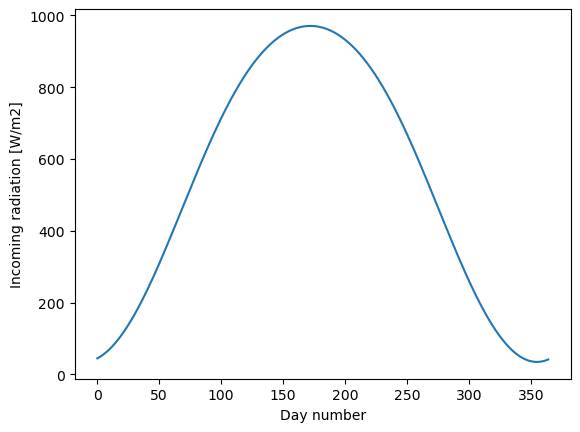

In [70]:
# Sun position calculation
h = np.arcsin(np.sin(declination_radians) * np.sin(lon) + np.cos(declination_radians) * np.cos(tau) * np.cos(lon)) # h is the angular height of the sun above the horizon
I_0h = S_0d * np.sin(h)
plt.plot(I_0h)
plt.xlabel('Day number')
plt.ylabel('Incoming radiation [W/m2]')


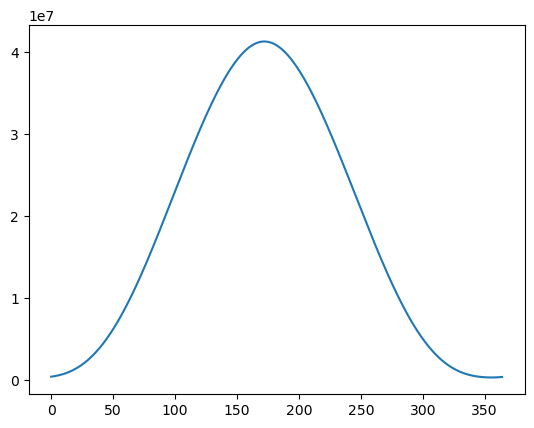

In [77]:
# Daily energy
tau_sunset = np.arccos(-np.tan(declination_radians) * np.tan(lon))
H_d0h = 24 * 3600 / np.pi * S_0d * (tau_sunset * np.sin(lon) * np.sin(declination_radians) 
                                    + np.cos(lon) * np.cos(declination_radians) * np.sin(tau_sunset))
plt.plot(H_d0h)

In [92]:
tau_2, tau_sunset

(0.5235987755982988,
 array([0.41888856, 0.42708809, 0.43584757, 0.44513175, 0.45490623,
        0.46513773, 0.47579429, 0.48684547, 0.49826241, 0.5100179 ,
        0.52208636, 0.53444388, 0.54706809, 0.55993821, 0.57303486,
        0.58634009, 0.59983725, 0.61351088, 0.6273467 , 0.64133148,
        0.65545298, 0.66969988, 0.68406171, 0.69852878, 0.71309212,
        0.72774346, 0.74247513, 0.75728004, 0.77215162, 0.78708381,
        0.80207098, 0.81710796, 0.83218992, 0.84731244, 0.86247139,
        0.877663  , 0.89288375, 0.90813041, 0.92339999, 0.93868976,
        0.95399718, 0.96931993, 0.98465588, 1.00000307, 1.01535973,
        1.03072422, 1.04609506, 1.06147093, 1.0768506 , 1.092233  ,
        1.10761715, 1.12300219, 1.13838736, 1.153772  , 1.16915553,
        1.18453748, 1.19991742, 1.21529505, 1.23067008, 1.24604235,
        1.26141171, 1.2767781 , 1.29214151, 1.30750198, 1.32285961,
        1.33821453, 1.35356692, 1.368917  , 1.38426504, 1.39961133,
        1.4149562 , 1.43030

In [93]:
# Hourly energy

# H_h0h = 24 * 3600 / np.pi * S_0d * ((tau_2 - tau_1) * np.sin(lon) * np.sin(declination_radians) 
#                                     + np.cos(lon) * np.cos(declination_radians) * np.sin((tau_2 - tau_1)))